# 16 姿态估计：骨架图片 → 关键点热图 → 坐标与骨架

用随机姿态的合成火柴人训练小型热图网络，每个输出通道对应一个关节。
这是“关键点热图”机制的可运行教学，不是已训练的人体姿态模型；不能据此对真实人物作可靠识别。


In [1]:
from pathlib import Path
import sys, os
for folder in [Path.cwd(), *Path.cwd().parents]:
    if (folder / "course_utils.py").exists():
        sys.path.insert(0, str(folder))
        break
else:
    raise FileNotFoundError("请从完整项目的根目录或 notebooks 目录运行。")
from course_utils import setup, device, save_figure
ROOT = setup(seed=42)
import numpy as np
import cv2
import matplotlib.pyplot as plt
from IPython import get_ipython
if get_ipython() is not None:
    get_ipython().run_line_magic("matplotlib", "inline")
import torch
from torch import nn
import torch.nn.functional as F
dev = device()
torch.set_num_threads(2)
print("计算设备:", dev)


计算设备: cpu


## 1. 生成图像、坐标和目标热图

关键点顺序：头、颈、左手、右手、髋、左脚、右脚。所有坐标按 (x,y) 保存。
训练与测试独立随机种子，尺度固定 32×32；关节角度与位置随机。

维度怎么读：图像数组原为 `[N,32,32]`，送入网络前补单通道维成为 **NCHW = `[N,1,32,32]`**。N 是图片数，C 是通道数，H/W 是高/宽。目标与预测热图是 `[N,K,32,32]`，本课 K=7；第 k 个通道只负责第 k 个关键点。坐标结果是 `[N,K,2]`，最后两项始终按 `(x,y)` 排列。

用一个仅供说明的 3×3 归一化热图读回坐标：

```text
[[0.01, 0.02, 0.01],
 [0.03, 0.70, 0.05],
 [0.02, 0.04, 0.12]]
```

这九个数的和为 1，每项对应一个候选像素位置，并非像素亮度。最大值 0.70 在第 1 行、第 1 列（从 0 开始数）；按行展开后 argmax 索引为 4。对于宽度 W=3，`x=4%3=1`、`y=4//3=1`，因此坐标是 `(1,1)`。实际代码用 W=32 做同样换算。某处响应最大只表示模型选了该位置，仍须与真值比较；示例中的 0.70 不是本次训练测量值。


输入图: (240, 32, 32) 热图: (240, 7, 32, 32)
坐标矩阵 [关键点,xy]:
 [[17.12  4.52]
 [17.12  8.52]
 [ 8.55 13.27]
 [22.97 14.63]
 [17.12 17.52]
 [13.55 25.35]
 [23.76 24.09]]
头部目标热图局部:
 [[0.01 0.05 0.18 0.4 ]
 [0.01 0.08 0.3  0.68]
 [0.01 0.08 0.3  0.69]
 [0.01 0.05 0.18 0.42]]


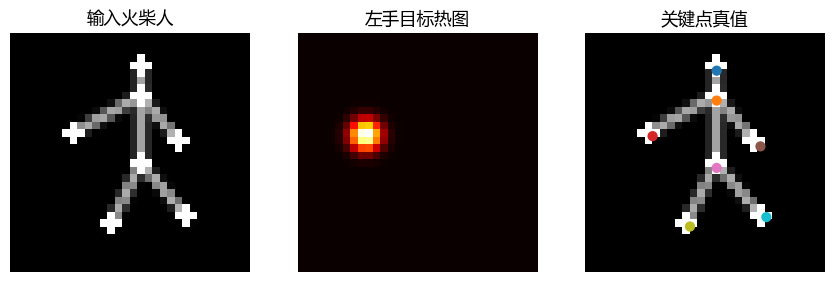

WindowsPath('D:/workspace/cv/cv-beginner-course/outputs/16_pose_inputs.png')

In [2]:
names=["head","neck","left hand","right hand","hip","left foot","right foot"]
edges=[(0,1),(1,2),(1,3),(1,4),(4,5),(4,6)]
def pose_data(n,seed):
    rng=np.random.default_rng(seed);images=[];points=[];maps=[]
    yy,xx=np.mgrid[:32,:32]
    for _ in range(n):
        cx=float(rng.uniform(14,18));y=float(rng.uniform(8,11))
        xy=np.array([[cx,y-4],[cx,y],[cx-rng.uniform(5,10),y+rng.uniform(-2,7)],
                     [cx+rng.uniform(5,10),y+rng.uniform(-2,7)],[cx,y+9],
                     [cx-rng.uniform(3,7),y+rng.uniform(15,18)],
                     [cx+rng.uniform(3,7),y+rng.uniform(15,18)]],np.float32)
        im=np.zeros((32,32),np.uint8)
        for a,b in edges:cv2.line(im,tuple(xy[a].astype(int)),tuple(xy[b].astype(int)),180,1,cv2.LINE_AA)
        for pt in xy:cv2.circle(im,tuple(pt.astype(int)),1,255,-1)
        heat=np.exp(-((xx[None]-xy[:,0,None,None])**2+(yy[None]-xy[:,1,None,None])**2)/(2*1.4**2))
        images.append(im/255.);points.append(xy);maps.append(heat)
    return np.array(images,np.float32),np.array(points,np.float32),np.array(maps,np.float32)

train_im,train_pts,train_hm=pose_data(240,10)
test_im,test_pts,test_hm=pose_data(48,999)
print("输入图:",train_im.shape,"热图:",train_hm.shape)
print("坐标矩阵 [关键点,xy]:\n",np.round(test_pts[0],2))
print("头部目标热图局部:\n",np.round(test_hm[0,0,3:7,13:17],2))
fig,axs=plt.subplots(1,3,figsize=(10,3))
axs[0].imshow(test_im[0],cmap="gray");axs[0].set_title("输入火柴人")
axs[1].imshow(test_hm[0,2],cmap="hot");axs[1].set_title("左手目标热图")
axs[2].imshow(test_im[0],cmap="gray");axs[2].scatter(test_pts[0,:,0],test_pts[0,:,1],c=range(7),cmap="tab10");axs[2].set_title("关键点真值")
for ax in axs:ax.axis("off")
save_figure("16_pose_inputs")


## 2. 热图回归网络

使用卷积提取空间特征，输出 7 个 32×32 热图 logits，再对每个关节的空间位置做 Softmax。
将目标高斯归一化成概率分布，最小化分布交叉熵。额外输入 x/y 坐标通道帮助小网络区分左右与上下；这也是明确的建模假设。


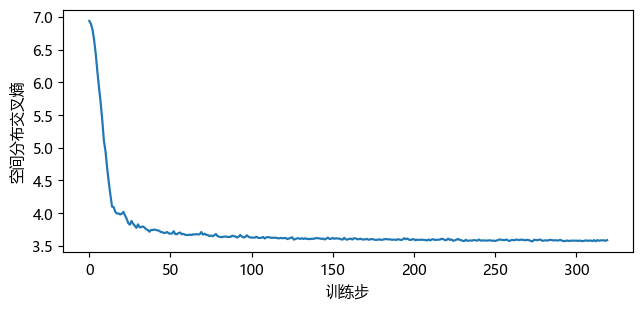

WindowsPath('D:/workspace/cv/cv-beginner-course/outputs/16_pose_loss.png')

In [3]:
class HeatmapNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.net=nn.Sequential(nn.Conv2d(3,16,5,padding=2),nn.ReLU(),
                               nn.Conv2d(16,24,5,padding=2),nn.ReLU(),
                               nn.Conv2d(24,24,5,padding=2),nn.ReLU(),
                               nn.Conv2d(24,7,1))
    def forward(self,x):
        yy,xx=torch.meshgrid(torch.linspace(-1,1,32,device=x.device),torch.linspace(-1,1,32,device=x.device),indexing="ij")
        xy=torch.stack([xx,yy])[None].expand(len(x),-1,-1,-1)
        return self.net(torch.cat([x,xy],dim=1))

model=HeatmapNet().to(dev)
optimizer=torch.optim.Adam(model.parameters(),lr=.003)
X=torch.from_numpy(train_im[:,None]).to(dev)
Y=torch.from_numpy(train_hm).to(dev)
losses=[]
for step in range(320):
    ids=torch.randint(len(X),(24,),device=dev)
    pred=model(X[ids]);target=Y[ids]
    target=target.flatten(2);target=target/target.sum(-1,keepdim=True)
    loss=-(target*pred.flatten(2).log_softmax(-1)).sum(-1).mean()
    optimizer.zero_grad();loss.backward();optimizer.step();losses.append(loss.item())
plt.figure(figsize=(7,3));plt.plot(losses);plt.xlabel("训练步");plt.ylabel("空间分布交叉熵")
save_figure("16_pose_loss")


## 3. 从热图读出坐标

每通道最大值的位置作为关节坐标。它的值称为响应强度，未经校准不能直接等同于可靠概率。
使用像素定位误差和 PCK@3 px，分别评价误差大小与三像素阈值内的比例。


保留集平均关键点误差=0.762 px；PCK@3px=1.000
预测坐标矩阵:
 [[17  4]
 [17  9]
 [ 9 14]
 [22 15]
 [17 18]
 [14 26]
 [24 25]]
预测左手热图局部:
 [[0.   0.   0.   0.  ]
 [0.   0.   0.   0.  ]
 [0.   0.01 0.02 0.02]
 [0.01 0.02 0.04 0.04]]


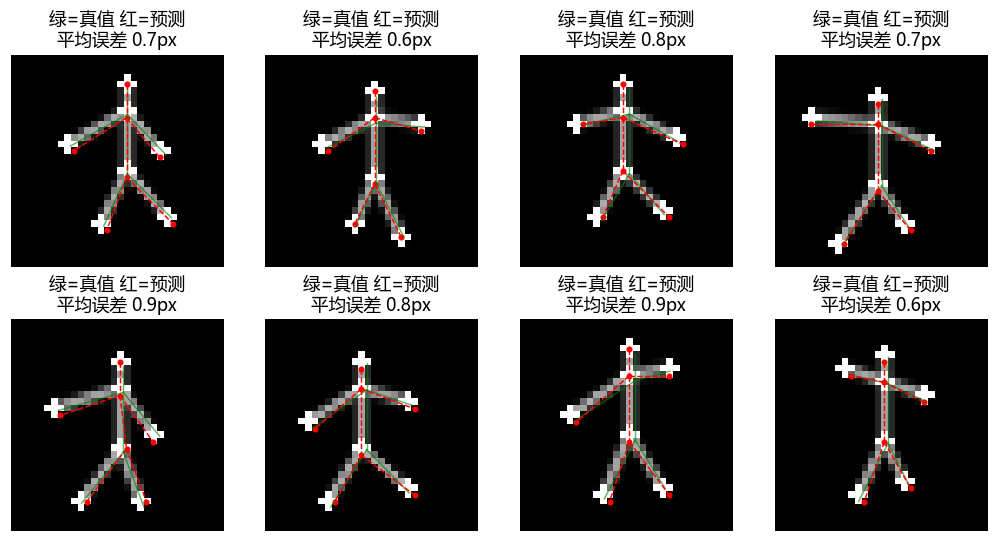

In [4]:
model.eval()
with torch.no_grad():
    logits=model(torch.from_numpy(test_im[:,None]).to(dev))
    pred_hm=logits.flatten(2).softmax(-1).reshape_as(logits).cpu().numpy()
flat=pred_hm.reshape(len(test_im),7,-1).argmax(-1)
pred_pts=np.stack([flat%32,flat//32],axis=-1)
errors=np.linalg.norm(pred_pts-test_pts,axis=-1)
print(f"保留集平均关键点误差={errors.mean():.3f} px；PCK@3px={(errors<3).mean():.3f}")
print("预测坐标矩阵:\n",pred_pts[0])
print("预测左手热图局部:\n",np.round(pred_hm[0,2,9:13,6:10],2))
fig,axs=plt.subplots(2,4,figsize=(12,6))
for i,ax in enumerate(axs.flat):
    ax.imshow(test_im[i],cmap="gray")
    for a,b in edges:
        ax.plot(test_pts[i,[a,b],0],test_pts[i,[a,b],1],"g-",lw=1,alpha=.6)
        ax.plot(pred_pts[i,[a,b],0],pred_pts[i,[a,b],1],"r--",lw=1)
    ax.scatter(pred_pts[i,:,0],pred_pts[i,:,1],c="red",s=10)
    ax.set_title(f"绿=真值 红=预测\n平均误差 {errors[i].mean():.1f}px");ax.axis("off")
save_figure("16_pose_outputs")
assert pred_hm.shape==(len(test_im),7,32,32) and np.isfinite(pred_hm).all()


## 4. 对比两类容易混淆的关节

左手/右手通道不同，即使外观类似也必须区分。遮挡会让热图不确定；低分辨率坐标还存在取整误差。


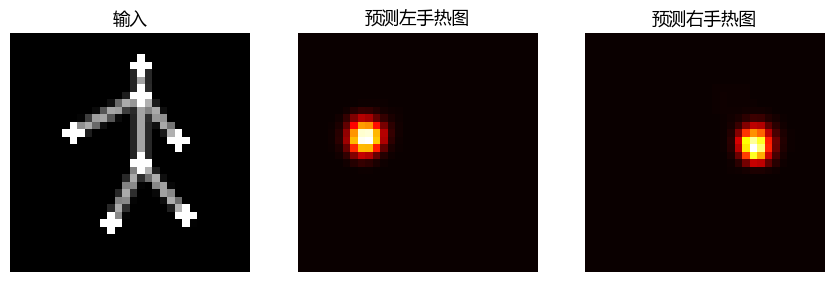

WindowsPath('D:/workspace/cv/cv-beginner-course/outputs/16_pose_heatmaps.png')

In [5]:
fig,axs=plt.subplots(1,3,figsize=(10,3))
for ax,im,title in zip(axs,[test_im[0],pred_hm[0,2],pred_hm[0,3]],["输入", "预测左手热图", "预测右手热图"]):
    ax.imshow(im,cmap="hot" if "热图" in title else "gray");ax.set_title(title);ax.axis("off")
save_figure("16_pose_heatmaps")


## 5. 学生练习与真实任务扩展

遮住一只手重新预测；去掉 x/y 坐标通道；改变高斯半径，观察 PCK。
真实人体姿态需要真实人物与关节标注、多人关联、尺度变化和遮挡处理，评价常见 PCK/OKS。

来源：[Stacked Hourglass 原论文](https://arxiv.org/abs/1603.06937)、[MMPose 官方项目](https://github.com/open-mmlab/mmpose)。本课仅学习热图回归机制，不复现这些大型模型的精度。
